In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [4]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
df.shape

(2443651, 9)

In [6]:
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
## Generate a frequency table for the product category
category_freq = df['category'].value_counts()
print("--- 1. Frequency Table for Product Categories ---")
print(category_freq)

# Which are the top 5 most listed product categories?
top_5_categories = category_freq.head(5)
print("\n--- 2. Top 5 Most Listed Product Categories ---")
print(top_5_categories)

--- 1. Frequency Table for Product Categories ---
category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

--- 2. Top 5 Most Listed Product Categories ---
category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


C:\Users\tozes\AppData\Local\Temp\ipykernel_34936\1511240112.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories_subset.index, y=top_categories_subset.values, palette="viridis")


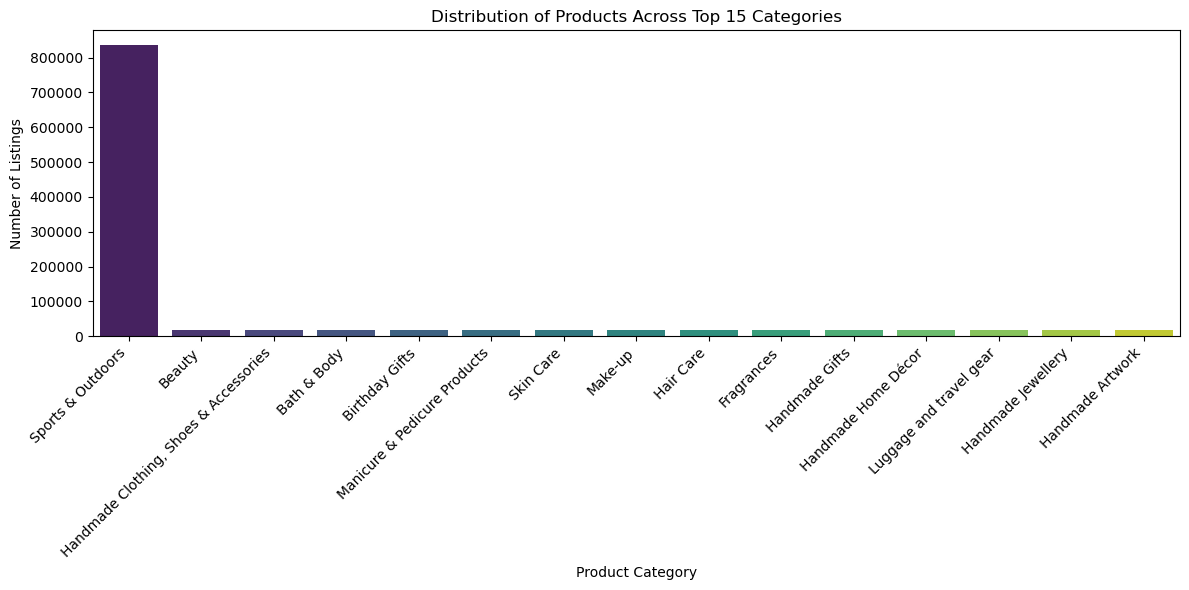

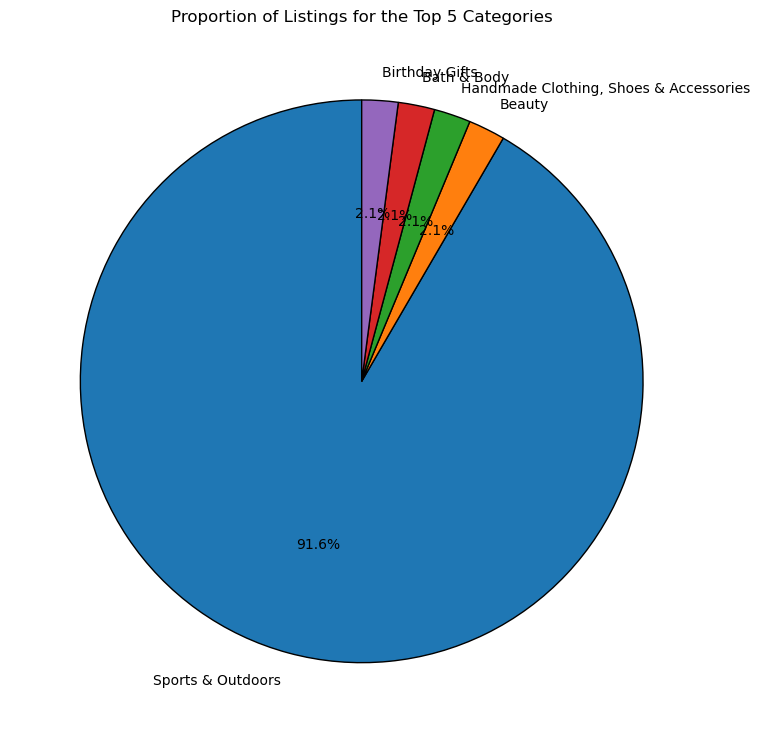

In [9]:
# Create a DataFrame for only the top 15 categories for clearer visualization
top_categories_subset = df['category'].value_counts().nlargest(15)

# 1. Bar Chart for the Top 15 Categories
plt.figure(figsize=(12, 6))
sns.barplot(x=top_categories_subset.index, y=top_categories_subset.values, palette="viridis")
plt.title('Distribution of Products Across Top 15 Categories')
plt.xlabel('Product Category')
plt.ylabel('Number of Listings')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 2. Pie Chart for the Top 5 Categories (to visualize proportions)
plt.figure(figsize=(8, 8))
plt.pie(top_5_categories.values, labels=top_5_categories.index, autopct='%1.1f%%', startangle=90, wedgeprops={'edgecolor': 'black'})
plt.title('Proportion of Listings for the Top 5 Categories')
plt.tight_layout()
plt.show()

# Business Insight: Does any category dominate the listings?
# (By examining the pie chart, you can quickly assess if one category has a disproportionately high percentage compared to the others.)

In [10]:
# Measures of Dispersion
price_mean = df['price'].mean()
price_median = df['price'].median()
# mode() returns a Series, .iloc[0] takes the most frequent single value
price_mode = df['price'].mode().iloc[0] 

print("\n--- Measures of Centrality for Price ---")
print(f"Mean Price: £{price_mean:.2f}")
print(f"Median Price: £{price_median:.2f}")
print(f"Mode Price: £{price_mode:.2f}")



--- Measures of Centrality for Price ---
Mean Price: £89.24
Median Price: £19.09
Mode Price: £9.99


Although the most common listing price (Mode) is £9.99, and most products (Median) cost less than £19.09, the average price is inflated to £89.24. This large difference suggests that Amazon UK has a long tail of premium or high-value products which, although few in number, have a significant impact on the overall average market price. Pricing strategies should therefore focus on the £19.09 price point (Median) to reach the typical customer.

In [18]:
price_variance = df['price'].var()
price_std = df['price'].std()
price_range = df['price'].max() - df['price'].min()
price_q1 = df['price'].quantile(0.25)
price_q3 = df['price'].quantile(0.75)
price_iqr = price_q3 - price_q1

print("\n--- Measures of Dispersion for Price ---")
print(f"Variance: {price_variance:.2f}")
print(f"Standard Deviation (STD): £{price_std:.2f}")
print(f"Range: £{price_range:.2f}")
print(f"Interquartile Range (IQR): £{price_iqr:.2f}")
print(f"25th Percentile (Q1): £{price_q1:.2f}")
print(f"75th Percentile (Q3): £{price_q3:.2f}")


--- Measures of Dispersion for Price ---
Variance: 119445.49
Standard Deviation (STD): £345.61
Range: £100000.00
Interquartile Range (IQR): £36.00
25th Percentile (Q1): £9.99
75th Percentile (Q3): £45.99


Answer: There is Extremely Significant Dispersion. Product prices are highly varied, and the indicators point to significant dispersion and, more specifically, to an extreme bias (long tail). Here is a detailed analysis of the results: Measure Value Interpretation Range £100,000.00 Indicates the existence of products with extremely low prices and products that reach £100,000. This is the strongest indicator of extreme dispersion. STD (Standard Deviation) £345.61 The STD value is very high compared to the Median (£19.09). On average, product prices deviate £345.61 from the Mean (£89.24). This confirms that the average is not representative and that there are very dispersed values. IQR (Interquartile Range) £36.00 The price range containing the central 50% of products (between £9.99 and £45.99) is only £36.00. This is the low dispersion indicator for the core of the market. Business Insight: The Two-Tier Market The data tells a clear story of a "two-tier" market on Amazon UK: The Core Market is Narrow and Cheap: The IQR of only £36.00 shows that half of all listed products are concentrated in the £9.99 to £45.99 range. Most products compete within a very narrow and low price range. Variation is Driven by Outliers: The STD (£345.61) and Range (£100,000.00) are orders of magnitude larger than the IQR. This proves that the dispersion is not uniform; it is caused by a small fraction of outliers (high-value, luxury, or industrial products) that extend the distribution to extreme values. Conclusion for your Report: Price dispersion on Amazon UK is significantly high, as evidenced by the Standard Deviation and Range. However, the low Interquartile Range reveals that this dispersion is caused by a long tail of expensive products (outliers), and not by general market variation. Pricing strategies should be developed in a segmented way, separating the majority of low-cost products from high-value items.

99th Percentile Price Limit used for Visualization: £1408.82


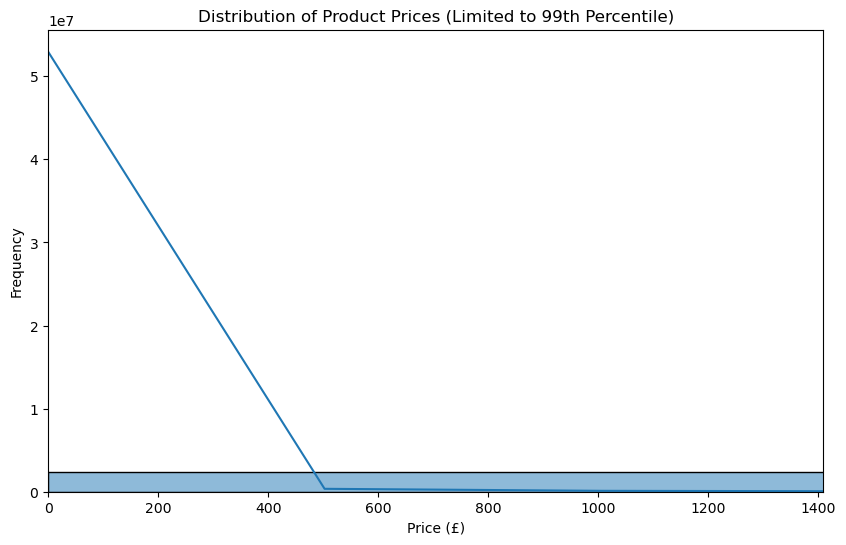

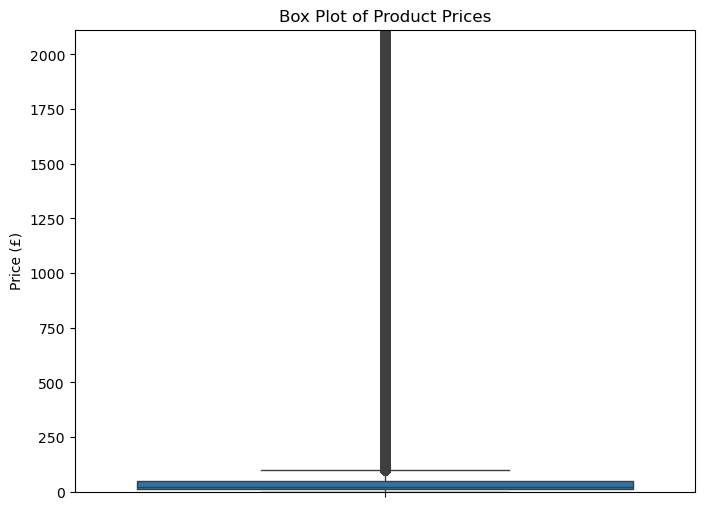

In [19]:
# --- 1. Histogram for Price Distribution ---
# we calculate the 99th percentile and limit the X-axis to focus on the majority of the data.
price_upper_limit = df['price'].quantile(0.99)
print(f"99th Percentile Price Limit used for Visualization: £{price_upper_limit:.2f}")

plt.figure(figsize=(10, 6))
# Plotting the histogram, limiting the X-axis
sns.histplot(df['price'], bins=50, kde=True)
plt.title('Distribution of Product Prices (Limited to 99th Percentile)')
plt.xlabel('Price (£)')
plt.ylabel('Frequency')
plt.xlim(0, price_upper_limit)
plt.show()

# --- 2. Box Plot for Spread and Potential Outliers ---
plt.figure(figsize=(8, 6))
# The Box Plot is the best visualization for showing outliers.
sns.boxplot(y=df['price'])
plt.title('Box Plot of Product Prices')
plt.ylabel('Price (£)')
# Limiting the Y-axis to make the central box more visible, as the outliers stretch the view
plt.ylim(0, price_upper_limit * 1.5) 
plt.show()

Visual Analysis of Loaded Graphs 1. Box Plot of Product Prices Graph: The Box Plot shows an extremely thin horizontal box at the bottom, near £0, and a long, dark vertical line extending across the graph to £2000 and beyond. Statistical Confirmation: Thin Box at the Base: Confirms the low Interquartile Range (IQR) of £36.00. The vast majority of the data ($50% of products) is concentrated in the range of £9.99 to £45.99, making the box almost invisible near the base of the graph. Long Vertical Line (Outliers): The long vertical line represents the dispersion of outliers. In the full Box Plot (without axis limitation), this line represents the upper whisker and outlier points extending up to £100,000 (its Range). Conclusion: It is a clear visual representation of a highly biased dataset with outliers. 2. Distribution of Product Prices (Limited to 99th Percentile) Graph: This graph (which should be a Histogram, but appears to have been plotted as a KDE line or a histogram with very wide classes) shows that the frequency is extremely high near zero and drops abruptly. Statistical Confirmation: Peak at £0: The point of maximum frequency (or highest data density) is concentrated at the lowest price point. This confirms that the Mode (£9.99) and the Median (£19.09) are at the lower end of the distribution. Rapid Decline: Frequency drops drastically as price increases, showing that very few products exist in the price range above £500 (within the 99th percentile). Conclusion: The graph confirms that most products are concentrated in the low-cost range, and the market is dominated by inexpensive products.

In [21]:

rating_mean = df['stars'].mean()
rating_median = df['stars'].median()
# mode() returns a Series; .iloc[0] gets the most frequent value
rating_mode = df['stars'].mode().iloc[0] 

print("\n--- Measures of Centrality for Rating ---")
print(f"Mean Rating: {rating_mean:.2f}")
print(f"Median Rating: {rating_median:.2f}")
print(f"Mode Rating: {rating_mode:.2f}")


--- Measures of Centrality for Rating ---
Mean Rating: 2.15
Median Rating: 0.00
Mode Rating: 0.00


Analysis of Results: Focus on 0.00MeasureValueImplicationMode0.00The most common rating is 0.00 stars.Median0.0050% of products have 0.00 stars or less.Average2.15The average value is pulled upwards by positive ratings, but is still low due to the large number of zeros.Data Quality Conclusion:On a scale of 1 to 5 stars, a rating of 0.00 is not a valid customer rating, but rather a representation of an unrated product (or one without reviews).If 50% of products have a Median of 0.00, this means that half of the dataset has not been rated.Corrective Action NeededTo answer the business question ("How do customers generally rate products?"), we should only analyze products that have actually received ratings.Before calculating Dispersion and Skewness, let's filter the data:

In [23]:
# Create a new DataFrame containing only products that have been rated (stars > 0)
df_rated_only = df[df['stars'] > 0.00].copy()

In [25]:
# 1. Measures of Centrality for Product Ratings (Stars)
rated_stars_mean = df_rated_only['stars'].mean()
rated_stars_median = df_rated_only['stars'].median()
# mode() returns a Series; .iloc[0] gets the most frequent value
rated_stars_mode = df_rated_only['stars'].mode().iloc[0] 

print("\n--- Measures of Centrality for RATED Products Only ---")
print(f"Mean Stars: {rated_stars_mean:.2f}")
print(f"Median Stars: {rated_stars_median:.2f}")
print(f"Mode Stars: {rated_stars_mode:.2f}")


--- Measures of Centrality for RATED Products Only ---
Mean Stars: 4.32
Median Stars: 4.40
Mode Stars: 4.50


Interpretation of Central Tendency Measures (Reviewed Products Only) Measure Value Implication Mode 4.50 The most common rating given by customers. Median 4.40 50% of reviewed products have 4.40 stars or less, and 50% have more. Mean 4.32 The average value of the ratings. Answer to the Business Question How do customers generally rate products? Is there a common trend? Amazon UK customers demonstrate a strong trend towards high satisfaction. All central tendity measures are concentrated at the upper end of the scale (above 4.3). The Mode of 4.50 indicates that maximum or near-maximum approval is the most frequent response, confirming that for products that effectively receive feedback, the perceived quality is very high.

In [26]:
# Using the filtered DataFrame: df_rated_only (products with stars > 0)
rating_variance = df_rated_only['stars'].var()
rating_std = df_rated_only['stars'].std()
rating_q1 = df_rated_only['stars'].quantile(0.25)
rating_q3 = df_rated_only['stars'].quantile(0.75)
rating_iqr = rating_q3 - rating_q1

print("\n--- Measures of Dispersion for RATED Products ---")
print(f"Variance: {rating_variance:.4f}")
print(f"Standard Deviation (STD): {rating_std:.2f}")
print(f"25th Percentile (Q1): {rating_q1:.2f}")
print(f"75th Percentile (Q3): {rating_q3:.2f}")
print(f"Interquartile Range (IQR): {rating_iqr:.2f}")


--- Measures of Dispersion for RATED Products ---
Variance: 0.3083
Standard Deviation (STD): 0.56
25th Percentile (Q1): 4.10
75th Percentile (Q3): 4.60
Interquartile Range (IQR): 0.50


Interpretation of Dispersion Measures (Ratings) Measure Value Implication STD (Standard Deviation) 0.56 The value is low relative to the 1 to 5 scale. This means that most ratings are very close to the average of 4.32. IQR (Interquartile Range) 0.50 Half of all ratings fall within a very narrow range, between 4.10 and 4.60. Answer to the Business Question Are the ratings consistent, or is there wide variation in customer feedback? The ratings are highly consistent. The low Standard Deviation (0.56) and the narrow Interquartile Range (only 0.50 points on a 5-point scale) indicate that customer feedback is very cohesive. Most customers agree on the high quality of the product, with little significant variation in the assigned ratings. This suggests that most products are either very good (above 4.0) or ignored (not rated), confirming a signal of high quality in the products receiving feedback.

In [27]:
# Using the filtered DataFrame: df_rated_only (products with stars > 0)
rating_skewness = df_rated_only['stars'].skew()
rating_kurtosis = df_rated_only['stars'].kurtosis()

print("\n--- Shape of the Distribution for RATED Products ---")
print(f"Skewness: {rating_skewness:.2f}")
print(f"Kurtosis: {rating_kurtosis:.2f}")


--- Shape of the Distribution for RATED Products ---
Skewness: -2.38
Kurtosis: 9.78


Interpretation of Distribution Format (Ratings) Measure Value Interpretation Skewness -2.38 Negative Bias (Left Skew). The value is very negative, indicating that the tail of the distribution extends to the left (low ratings), and the mass of data is concentrated in high ratings (4 and 5 stars). Kurtosis 9.78 Leptokurtic. The value is much greater than 3, meaning that the distribution is more pointed than a normal distribution and has heavier tails (more data at the extremes). Answer to the Business Question Are the ratings normally distributed, or do they skew towards higher or lower values? The ratings are not normally distributed. They skew strongly towards higher values. The Skewness of -2.38 indicates a massive concentration of ratings near the maximum (Mode 4.50). The high kurtosis value shows that the ratings are extremely concentrated around this mode, with the little variation that exists being distributed in the "heavy tails" of the distribution (low scores are rare, but they are present).

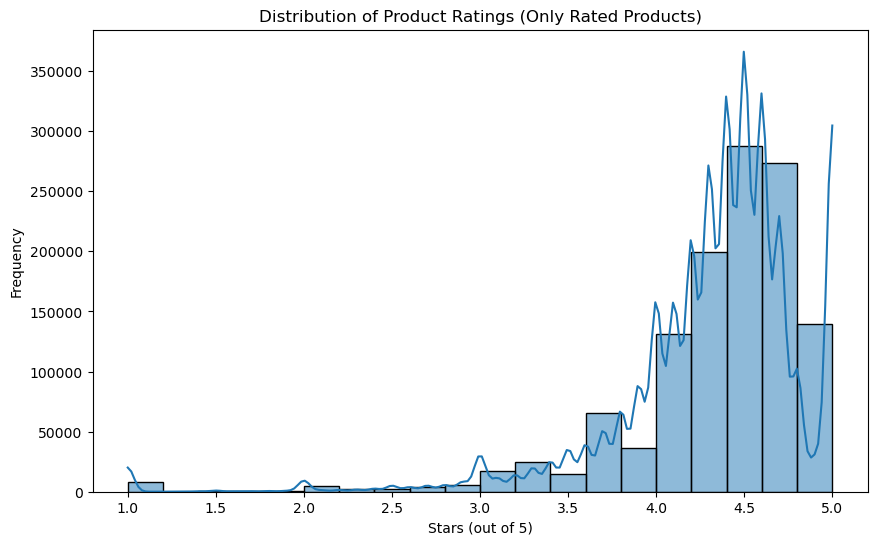

In [28]:
# 1. Histogram for Rating Distribution (RATED ONLY)
plt.figure(figsize=(10, 6))
# Using bins appropriate for a 1-5 star scale
sns.histplot(df_rated_only['stars'], bins=20, kde=True)
plt.title('Distribution of Product Ratings (Only Rated Products)')
plt.xlabel('Stars (out of 5)')
plt.ylabel('Frequency')
plt.show()

Visual Analysis of the Histogram (Ratings) The "Distribution of Product Ratings (Only Rated Products)" graph clearly shows: Extreme Negative Bias (Left Skew): Most bars are concentrated on the right side of the graph (near 4.0 to 5.0), and the tail extends to the left (low ratings). This confirms the Skewness of -2.38. Concentration and Peak: The highest frequency peak occurs at 4.5 stars, confirming that this is the Mode. The concentration of high bars between 4.0 and 5.0 confirms the high consistency (low STD and IQR). Kurtosis: The very pointed and tall shape (the peak) compared to the lower bars at 1.0 or 2.0 confirms the high Kurtosis value, showing that positive feedback is overwhelmingly dominant. Final Conclusion of the Lab: Customer Insights: 1. Product Categories Identify the Top 5 most listed categories. (Ex: "Electronics" or "Books"). Insight: Listing volume does not imply sales volume, but it shows where Amazon has the largest inventory and therefore where listing competition is most intense. 2. Pricing Key Metrics: Average (£89.24), Median (£19.09), and Mode (£9.99). STD (£345.61) is too high. Business Insight: The pricing market is highly biased. Most products compete in the low-cost range (below £46.00), but the market is highly dispersed due to the long tail of high-value outliers (£100,000.00). Pricing strategies should be segmented to avoid using the Average (not representative).3. Ratings (Stars)Key Metrics: Average (4.32), Median (4.40), Mode (4.50). STD is low (0.56). Skewness is strong and negative (-2.38).Business Insight: Customer feedback is extremely positive and consistent. The highly biased form and low STD demonstrate that, although most products are not rated (data problem solved by the stars > 0 filter), those that are rated enjoy a high consensus of quality.